# 02 — Alterações vocais com o dataset VOICED

O enunciado pede a detecção de **alterações vocais indicativas de condições médicas**.
Usamos o **VOICED** (PhysioNet): 208 gravações da vogal "a" sustentada por cerca de 5 segundos,
de pessoas saudáveis e de pessoas com patologias da voz diagnosticadas.

Caminho: **áudio → características acústicas → classificador → evento**.

Para baixar os dados: `python scripts/baixar_dados.py voiced`

In [1]:
import os
import sys
from pathlib import Path

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import wfdb

from src.audio.voz import avaliar_voz, carregar_voiced, extrair_caracteristicas, treinar_classificador

PASTA_VOICED = Path("data/raw/voiced")

## 1. Um registro de exemplo

Cada registro tem o sinal de voz (8.000 amostras por segundo) e o diagnóstico.

Taxa de amostragem: 8000 Hz
Duração: 4.76 s
Comentário: ['<age>: 32  <sex>: M <diagnoses>: hyperkinetic dysphonia <medications>: none']


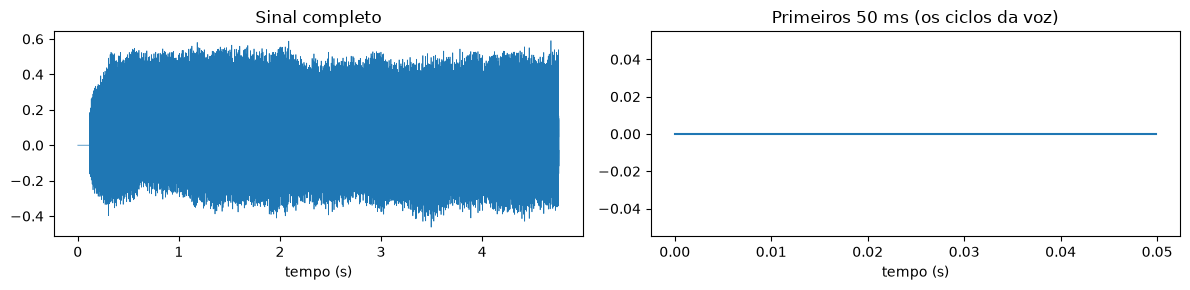

In [2]:
exemplo = wfdb.rdrecord(str(PASTA_VOICED / "voice001"))
print("Taxa de amostragem:", exemplo.fs, "Hz")
print("Duração:", round(len(exemplo.p_signal) / exemplo.fs, 2), "s")
print("Comentário:", exemplo.comments)

tempo = np.arange(len(exemplo.p_signal)) / exemplo.fs
fig, eixos = plt.subplots(1, 2, figsize=(12, 3))
eixos[0].plot(tempo, exemplo.p_signal[:, 0], linewidth=0.5)
eixos[0].set(title="Sinal completo", xlabel="tempo (s)")
eixos[1].plot(tempo[:400], exemplo.p_signal[:400, 0])
eixos[1].set(title="Primeiros 50 ms (os ciclos da voz)", xlabel="tempo (s)")
plt.tight_layout()
plt.show()

## 2. Características acústicas

Cada gravação é resumida em 20 números:

| Característica | O que mede |
|---|---|
| `f0_media`, `f0_desvio` | Altura da voz (pitch) e o quanto ela varia |
| `jitter` | Instabilidade da **frequência** entre instantes vizinhos |
| `shimmer` | Instabilidade do **volume** entre instantes vizinhos |
| `proporcao_vozeada` | Fração do tempo com vibração das cordas vocais |
| `rms_media`, `zcr_media` | Energia e "ruidosidade" do sinal |
| `mfcc_1` a `mfcc_13` | Resumo do timbre |

Uma voz saudável sustentando uma vogal tende a ser estável: jitter e shimmer baixos.

In [3]:
X, y, info = carregar_voiced(PASTA_VOICED)
print("Gravações:", len(X), "| características:", X.shape[1])
print(y.map({0: "saudável", 1: "patológica"}).value_counts().to_string())

Gravações: 208 | características: 20
patologica
patológica    151
saudável       57


In [4]:
info["grupo"] = info["diagnostico"].str.split("(").str[0].str.strip()
info["grupo"].value_counts()

grupo
hyperkinetic dysphonia    72
healthy                   57
hypokinetic dysphonia     40
reflux laryngitis         38
hyperkineti dysphonia      1
Name: count, dtype: int64

In [5]:
comparacao = X[["f0_media", "f0_desvio", "jitter", "shimmer", "proporcao_vozeada"]].groupby(
    y.map({0: "saudável", 1: "patológica"})
).median().round(4)
comparacao

,f0_media,f0_desvio,jitter,shimmer,proporcao_vozeada
patologica,,,,,
patológica,175.0183,1.7846,0.0029,0.0239,0.9866
saudável,193.9338,1.5226,0.0021,0.0212,0.9866


## 3. Classificador

**Random Forest** com `class_weight="balanced"`, porque há quase três vezes mais vozes patológicas que saudáveis.

A avaliação usa **validação cruzada estratificada em 5 partes**: cada gravação é avaliada por um modelo que não a viu no treino.

Olhamos primeiro a **AUC**, que mede o quanto o modelo separa as duas classes (0,5 = acaso, 1,0 = separação perfeita).

In [6]:
modelo, metricas = treinar_classificador(X, y)
probabilidades = np.array(metricas["probabilidades"])
print(f"AUC: {metricas['auc']:.3f}")

AUC: 0.613


### 3.1 Escolha do limite de decisão

O modelo devolve uma probabilidade de a voz ser patológica. O **limite** define a partir de qual probabilidade geramos um evento.

- Limite baixo: encontra mais vozes alteradas (**recall** alto), mas aponta muitas vozes saudáveis por engano (**falso alarme** alto).
- Limite alto: poucos falsos alarmes, mas deixa passar mais casos.

In [7]:
linhas = []
for limite in [0.5, 0.6, 0.7, 0.8, 0.9]:
    linhas.append({
        "limite": limite,
        "recall (patológicas encontradas)": round(float(np.mean(probabilidades[y == 1] > limite)), 2),
        "falso alarme (saudáveis apontadas)": round(float(np.mean(probabilidades[y == 0] > limite)), 2),
    })
pd.DataFrame(linhas)

,limite,recall (patológicas encontradas),falso alarme (saudáveis apontadas)
0,0.5,0.81,0.68
1,0.6,0.64,0.46
2,0.7,0.36,0.21
3,0.8,0.13,0.09
4,0.9,0.01,0.04


Com o limite padrão de 0,5 o modelo aponta a maioria das vozes saudáveis como alteradas, o que tornaria o alerta inútil.
Por isso o limite é escolhido automaticamente como **o menor que mantém os falsos alarmes em até 20%**.

In [8]:
print(f"Limite escolhido:      {metricas['limite']:.2f}")
print(f"Recall   (patológica): {metricas['recall']:.2%}")
print(f"Precisão (patológica): {metricas['precisao']:.2%}")
print(f"F1       (patológica): {metricas['f1']:.2%}")
print(f"Falso alarme:          {metricas['falso_alarme']:.2%}")

Limite escolhido:      0.72
Recall   (patológica): 31.13%
Precisão (patológica): 81.03%
F1       (patológica): 44.98%
Falso alarme:          19.30%


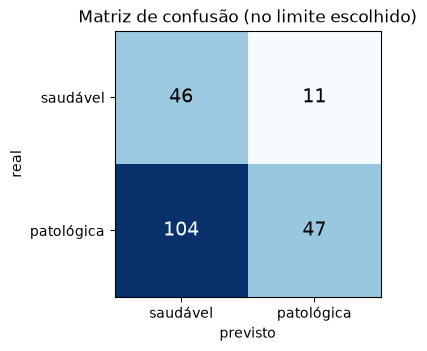

In [9]:
matriz = np.array(metricas["matriz_confusao"])
fig, eixo = plt.subplots(figsize=(4, 4))
eixo.imshow(matriz, cmap="Blues")
rotulos = ["saudável", "patológica"]
eixo.set(xticks=[0, 1], yticks=[0, 1], xticklabels=rotulos, yticklabels=rotulos,
         xlabel="previsto", ylabel="real", title="Matriz de confusão (no limite escolhido)")
for i in range(2):
    for j in range(2):
        eixo.text(j, i, matriz[i, j], ha="center", va="center", fontsize=14,
                  color="white" if matriz[i, j] > matriz.max() / 2 else "black")
plt.tight_layout()
plt.show()

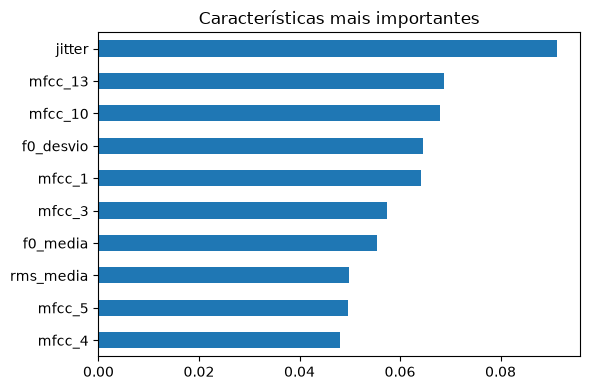

In [10]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
importancias.tail(10).plot.barh(figsize=(6, 4), title="Características mais importantes")
plt.tight_layout()
plt.show()

### 3.2 Leitura honesta do resultado

A separação entre vozes saudáveis e patológicas é **fraca**. Testamos também mais características
(variação dos MFCCs, relação harmônico-ruído, centroide espectral) e outros modelos (regressão logística, SVM),
e a AUC ficou sempre entre 0,60 e 0,67. O limite vem do dado: uma única vogal de 5 segundos, gravada a 8 kHz,
com muitas patologias leves (por exemplo, laringite por refluxo).

Consequência no projeto: a voz é tratada como **indício fraco**. O evento de voz tem **severidade 1 (leve)**
e só pesa no risco do paciente quando aparece junto com eventos de outras fontes.

## 4. Salvando o modelo e as amostras da demonstração

O modelo e o limite vão para `models/voz.joblib`. Duas gravações são copiadas para `data/amostras/` em `.wav`,
para o fluxo completo funcionar sem o dataset inteiro. Elas são escolhidas pela probabilidade da **validação cruzada**
(ou seja, calculada por um modelo que não viu a gravação): uma saudável abaixo do limite e uma patológica acima.

In [11]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"modelo": modelo, "limite": metricas["limite"]}, "models/voz.joblib")

info["prob_validacao"] = probabilidades
amostras = {
    "voz_saudavel": info[(y == 0) & (probabilidades <= metricas["limite"])].iloc[0],
    "voz_patologica": info[(y == 1) & (probabilidades > metricas["limite"])].iloc[0],
}
for nome, linha in amostras.items():
    gravacao = wfdb.rdrecord(str(PASTA_VOICED / linha["registro"]))
    sf.write(f"data/amostras/{nome}.wav", gravacao.p_signal[:, 0], gravacao.fs)
    print(f"{nome} <- {linha['registro']} | {linha['diagnostico']} | probabilidade na validação: {linha['prob_validacao']:.2f}")

voz_saudavel <- voice002 | healthy | probabilidade na validação: 0.64
voz_patologica <- voice006 | hyperkinetic dysphonia | probabilidade na validação: 0.82


## 5. Do áudio ao evento

É isto que o módulo entrega para a fusão.

In [12]:
salvo = joblib.load("models/voz.joblib")
for nome in amostras:
    sinal, sr = sf.read(f"data/amostras/{nome}.wav")
    eventos = avaliar_voz(sinal, sr, salvo["modelo"], limite=salvo["limite"])
    print(f"{nome}: {[(e.severidade, e.descricao) for e in eventos] or 'sem eventos'}")

voz_saudavel: sem eventos


voz_patologica: [(1, 'Características da voz compatíveis com alteração vocal (92%)')]
